**Icha Meisya Kurnia (25031554047)**

**Putri Najwa Zuleyka Al Hasni (25031554076)**

In [ ]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
import pandas as pd
import requests
from sklearn.feature_extraction.text import TfidfVectorizer

url = "https://api.spaceflightnewsapi.net/v4/articles/?limit=100"
response = requests.get(url)
data = response.json()

articles = [item['summary'] for item in data['results']]
df = pd.DataFrame({'prepro': articles})

df = df.dropna().reset_index().drop(columns=['index'])
df_pre = df['prepro']

vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(df_pre)
df_FE = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())

**K-MEANS**

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from wordcloud import WordCloud

In [ ]:
k = range(1, 7)
inertia = []

for i in k:
    km_model = KMeans(n_clusters=i, random_state=10)
    km_model.fit(df_FE)
    inertia.append(km_model.inertia_)

print(list(k))
print(inertia)

[1, 2, 3, 4, 5, 6]
[96.55461243770554, 94.3222714913717, 92.61338833521485, 87.8836546937469, 86.27611211576647, 84.97972328942039]


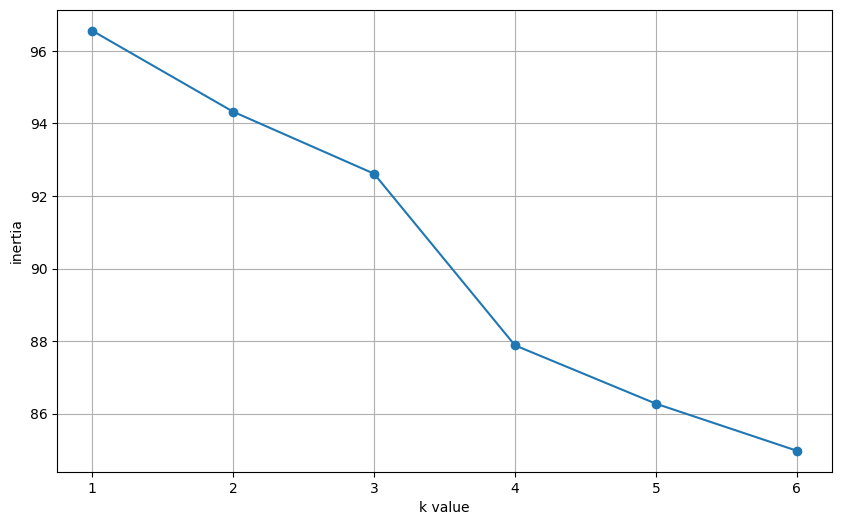

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(k, inertia, marker='o')
plt.xlabel('k value')
plt.ylabel('inertia')
plt.grid()
plt.show()

In [ ]:
n_clusters = 4

In [ ]:
kM = KMeans(n_clusters=n_clusters, random_state=10).fit(df_FE)
kM

KMeans(n_clusters=4, random_state=10)

In [ ]:
df['Kmeans_label'] = kM.labels_
df.head()

,prepro,Kmeans_label
0,Liftoff of the Starlink 15-16 mission from Spa...,3
1,Description This 360-degree look at Neretva Va...,3
2,"Written by Margaret Deahn, Ph.D. candidate at ...",3
3,Four rockets are set to launch this week from ...,3
4,"Over 1,645 Martian days, NASA’s Perseverance M...",1


**Silhouette Score**

In [ ]:
from sklearn import metrics
labels = kM.labels_
metrics.silhouette_score(df_FE, labels, metric='euclidean')

np.float64(0.05180218489353772)

**World Cloud**

Kmeans for cluster 0


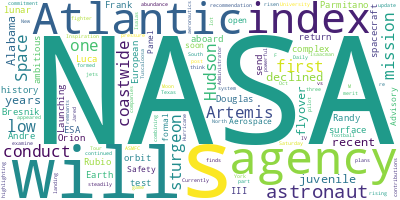

In [ ]:
c = 0
print('Kmeans for cluster ' + str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ' '.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 1


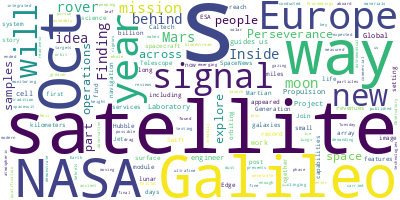

In [ ]:
c = 1
print('Kmeans for cluster ' + str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ' '.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 2


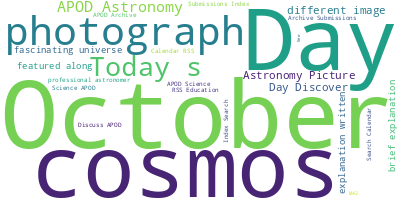

In [ ]:
c = 2
print('Kmeans for cluster ' + str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ' '.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 3


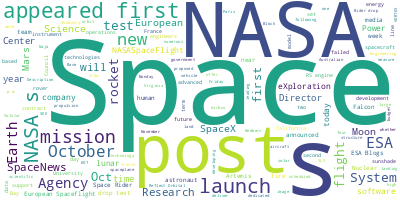

In [ ]:
c = 3
print('Kmeans for cluster ' + str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ' '.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

**HIERARCHICAL**

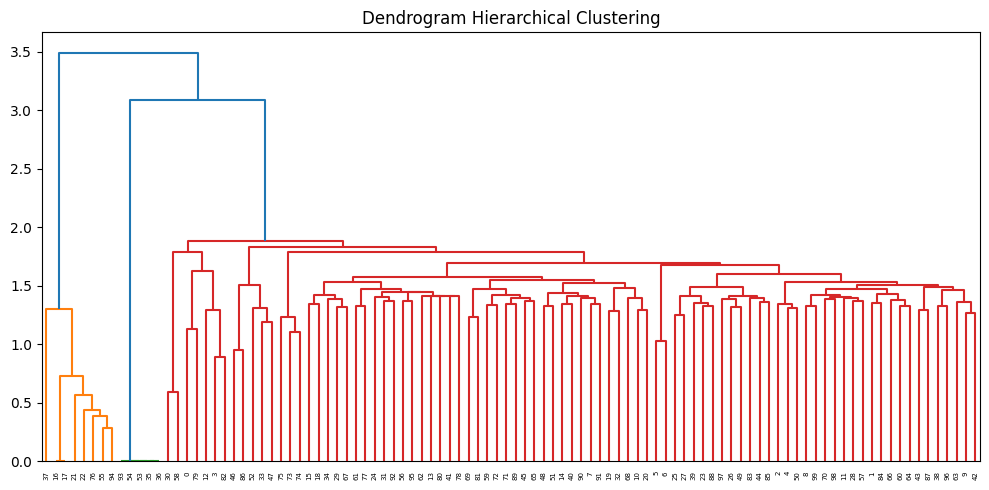

HIERARCHICAL
Silhouette Score Hierarchical: 0.09523388812139641


In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage

linkage_data = linkage(df_FE, method='ward', metric='euclidean')
plt.figure(figsize=(10, 5))
dendrogram(linkage_data)
plt.title("Dendrogram Hierarchical Clustering")
plt.tight_layout()
plt.show()

from sklearn.cluster import AgglomerativeClustering

hierarchical_cluster = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
df['Ward_label'] = hierarchical_cluster.fit_predict(df_FE)

print("HIERARCHICAL")
print("Silhouette Score Hierarchical:", metrics.silhouette_score(df_FE, df['Ward_label'], metric='euclidean'))


**World Cloud**

Hierarchical for cluster 0


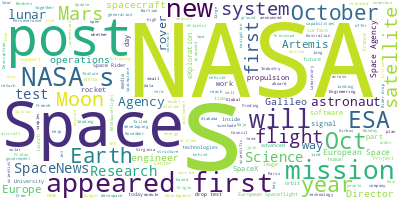

In [ ]:
c = 0
print('Hierarchical for cluster '+str(c))
df_c = df[df['Ward_label'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Hierarchical for cluster 1


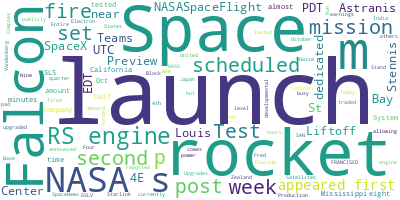

In [ ]:
c = 1
print('Hierarchical for cluster '+str(c))
df_c = df[df['Ward_label'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Hierarchical for cluster 2


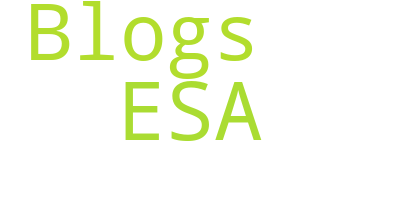

In [ ]:
c = 2
print('Hierarchical for cluster '+str(c))
df_c = df[df['Ward_label'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Hierarchical for cluster 3


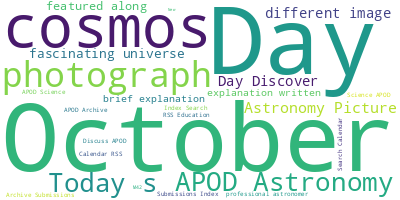

In [ ]:
c = 3
print('Hierarchical for cluster '+str(c))
df_c = df[df['Ward_label'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

**ANALISIS**

Proses pengelompokan dokumen dilakukan menggunakan algoritma K-Means, di mana evaluasi nilai inertia untuk k = 1 hingga k = 6 menunjukkan penurunan dari 96.55 ke 84.98 hingga akhirnya dipilih k = 4. Pengujian model menghasilkan Silhouette Score sebesar 0.0518, yang mengindikasikan bahwa batas antar kluster masih sangat samar dan tingkat tumpang-tindih antar-dokumen tergolong tinggi. Untuk memahami karakteristiknya, setiap dokumen diberi label kluster (Kmeans_label) dan dianalisis menggunakan visualisasi WordCloud dengan mengidentifikasi kata kunci dominan di setiap kelompok.

Analisis ini juga menggunakan metode Hierarchical Clustering (Agglomerative Clustering) untuk memetakan hubungan bertingkat antar-dokumen melalui dendrogram tanpa harus menentukan jumlah kluster di awal, sekaligus menguji pemisahan kluster berbasis struktur pohon yang menghasilkan performa lebih baik.